# Simulation of `phase2_assumptions.md`

This run implements the station-group setup assumptions in [phase2_assumptions.md](phase2_assumptions.md), using the Year 3 resources and 75% setup reductions at every station (relative to the original project inputs; previously reduced stations are not reduced again).

**Operational interpretation:**
- A workcell set means all parallel machines at one numbered station (for example, all six machines at 5-A), rather than all of Fabrication or Assembly.
- The complete station is set up once for **each product lot**, even when an earlier lot of that model was prepared. Setup happens when its first unit reaches the head of the station queue. Existing station work and maintenance finish first; all station machines are reserved during setup and while waiting for the setup team.
- Setup labor is `machine count × efficiency-adjusted setup time`. Elapsed setup is that labor divided by the assigned setup crew. Crew defaults to the station machine count; `SETUP_CREW` below overrides it. Operators come from the existing shared cell pools and are unavailable elsewhere while setting up. Crews are acquired atomically, in the pool's priority/FIFO order.
- A prepared lot remains ready at that station until it finishes. Its units can share machines with any other prepared product without further per-unit changeover setup. Zero setup inputs stay zero.
- Arrivals retain the latest experiment: **M860 → M970 → M1080**, one kit per recalculated arrival interval, with no station lot gates or WIP cap. This is an equal-thirds arrival mix; the demand targets retain their original mix.
- EOQ group identifiers retain the existing branch quantities, scrap planning, and component matching. They do not impose processing batches: matched assemblies leave immediately when their components are available.

These choices make the prose assumptions concrete. In particular, the station is unavailable during its group setup; prepared products may mix freely afterward. Part flow time starts at the oldest constituent kit's actual arrival; WIP counts component and assembly items.

**SPC in both cells:** Fabrication (1–8) and Assembly (9–12) use `scrap_scale=0.25`, a 75% reduction in every station/model scrap probability. Zero scrap stays zero. Scrap allowances, component requirements, and kit interarrival time are recalculated for the same planned finished output; therefore fewer input kits are required. The product rotation and resources stay the same. The input table below reports the actual recalculated arrival interval.

## 1. Scenario inputs and setup crews

Change `YEAR` and `SETUP_CREW` here. This notebook uses the station-group setup policy throughout the detailed run. The tables show resources, product inputs, and elapsed setup times after efficiency and crew adjustment.

In [22]:
import os
from dataclasses import replace
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lcd_sim.params import get_scenario, MODELS, STATIONS, STATION_INFO
from lcd_sim.stats import run, run_replications
from lcd_sim import plots as P

YEAR = 3
N_REPS = 10
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))
SPC_SCRAP_SCALE = 0.25  # SPC in both Fab and Asm: 75% less scrap
SETUP_CREW = {}   # e.g. {"5-A": 3}; default is one operator per machine at each station
sc = get_scenario(YEAR, release_mode="cyclic", setup_scope="workcell", setup_crew=SETUP_CREW, scrap_scale=SPC_SCRAP_SCALE)
print(f"Year {YEAR}; {sc.warmup_weeks}-week warm-up; {sc.run_weeks}-week measurement")
print(f"Arrivals: M860 → M970 → M1080; {sc.kit_interarrival_min:.4f} productive min/kit")
print(f"Operators per shift: {sc.operators}")
station_inputs, product_inputs = sc.describe()
display(product_inputs)
display(station_inputs)
setup_inputs = pd.DataFrame([
    {"Station": ws, "Machines": sc.machines[ws],
     "Setup crew": sc.setup_crew.get(ws, sc.machines[ws]),
     **{f"{model} elapsed setup (min)": sc.machines[ws] * sc.op_times(model, ws)["setup"] / sc.setup_crew.get(ws, sc.machines[ws])
        if station_inputs.loc[ws, f"Time/part {model}"] > 0 else None for model in MODELS}}
    for ws in STATIONS
]).set_index("Station")
display(setup_inputs)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.3f}".format)
print(f"SPC: Fab and Asm scrap probabilities multiplied by {sc.scrap_scale:.2f}")
scrap_inputs = pd.DataFrame({model: {ws: sc.scrap_rate(model, ws) for ws in STATIONS} for model in MODELS})
scrap_inputs.index.name = "Station"
display(scrap_inputs.rename(columns=lambda model: f"{model} scrap probability"))


Year 3; 2-week warm-up; 8-week measurement
Arrivals: M860 → M970 → M1080; 1.1834 productive min/kit
Operators per shift: {'Fab': 7, 'Asm': 13}


,Demand,EOQ,Lots_per_year,Planned_yield,Sent to KIT (1-M),Sent to KB (4-A),Sent to DISP (2-M),Sent to PWR (3-A/5-A),Sent to BL (6-A),Sent to ASM (7-M/8-A/9-M/10-M/11-A/12-M),Kits_per_year,Sent to ASM (8-A/9-M/10-M/11-A/12-M)
Model,,,,,,,,,,,,
M860,63877,754,85,0.942,801,791,801,799,787,785.000,68085,NaN
M970,55296,596,93,0.961,620,614,620,620,613,NaN,57660,611.000
M1080,61516,655,94,0.957,685,676,685,684,674,NaN,64390,672.000


,Description,Type,Cell,Machines,Efficiency,Time/part M860,Time/part M970,Time/part M1080,Setup M860,Setup M970,Setup M1080,Qty/lot M860,Qty/lot M970,Qty/lot M1080,Scrap factor M860,Scrap factor M970,Scrap factor M1080,PM_every_units,PM_min,MTBF_hr,Repair_min,Units_between_failures
Station,,,,,,,,,,,,,,,,,,,,,,
1-M,Unpack and label components,M,Fab,2,0.900,1.742,1.851,2.287,16.670,0.000,0.000,801,620.000,685.000,1.062,1.040,1.046,NaN,NaN,NaN,NaN,NaN
2-M,Sanitize LC displays and PCBs,M,Fab,2,0.950,1.135,1.548,1.651,21.050,0.000,0.000,801,620.000,685.000,1.062,1.040,1.046,NaN,NaN,100.000,10.000,"4,182.000"
3-A,Connect display to power strip,A,Fab,2,1.050,0.564,1.404,1.686,1.190,2.380,2.860,799,620.000,684.000,1.060,1.039,1.044,"12,000.000",10.000,50.000,30.000,"2,502.000"
4-A,Tack keyboard inputs to display,A,Fab,1,1.020,0.969,0.484,0.678,1.960,2.450,3.430,791,614.000,676.000,1.049,1.030,1.031,"12,000.000",20.000,75.000,60.000,"6,221.000"
5-A,Bond power strip to PCB and LCD,A,Fab,6,0.990,2.697,6.459,7.251,3.790,15.150,16.410,799,620.000,684.000,1.054,1.035,1.041,"12,000.000",20.000,250.000,120.000,"2,787.000"
6-A,Insert backlights and sensors,A,Fab,3,0.950,1.242,1.964,3.308,10.530,0.000,0.000,787,613.000,674.000,1.044,1.027,1.028,"6,000.000",10.000,60.000,60.000,"1,666.000"
7-M,Verify alignment and bonds,M,Fab,1,0.900,1.316,NaN,NaN,13.330,NaN,NaN,785,NaN,NaN,1.041,NaN,NaN,NaN,NaN,100.000,15.000,"4,561.000"
8-A,Power up test on components,A,Fab,2,0.950,1.350,1.556,2.074,2.630,2.630,3.950,785,611.000,672.000,1.033,1.025,1.025,"6,000.000",10.000,250.000,90.000,"9,050.000"
9-M,Solder subassemblies and connectors,M,Asm,6,0.930,3.372,7.272,8.642,5.380,0.000,0.000,785,611.000,672.000,1.023,1.017,1.018,NaN,NaN,NaN,NaN,NaN


,Machines,Setup crew,M860 elapsed setup (min),M970 elapsed setup (min),M1080 elapsed setup (min)
Station,,,,,
1-M,2,2,16.667,0.000,0.000
2-M,2,2,21.053,0.000,0.000
3-A,2,2,1.190,2.381,2.857
4-A,1,1,1.961,2.451,3.431
5-A,6,6,3.788,15.152,16.414
6-A,3,3,10.526,0.000,0.000
7-M,1,1,13.333,NaN,NaN
8-A,2,2,2.632,2.632,3.947
9-M,6,6,5.376,0.000,0.000


SPC: Fab and Asm scrap probabilities multiplied by 0.25


,M860 scrap probability,M970 scrap probability,M1080 scrap probability
Station,,,
1-M,0.000,0.000,0.000
2-M,0.003,0.001,0.001
3-A,0.005,0.004,0.003
4-A,0.007,0.005,0.005
5-A,0.013,0.010,0.015
6-A,0.003,0.003,0.003
7-M,0.007,0.000,0.000
8-A,0.010,0.007,0.007
9-M,0.010,0.007,0.007


## 2. Plant flow and model checks

One replication illustrates the assumptions. Charts with a grey warm-up band include the initial two weeks; summary statistics use the following eight weeks. A station-group setup reserves every machine at that station. Prepared product lots can then share the station without per-unit changeover setup.

Accounting and operator checks: {'lot violations (must be 0)': 0, 'closed lots with items still owed (must be 0)': 0, 'negative owed counts (must be 0)': 0, 'finished > EOQ x plan (must be 0)': 0, 'max operator utilization (<= 1)': 0.8557751217590467}


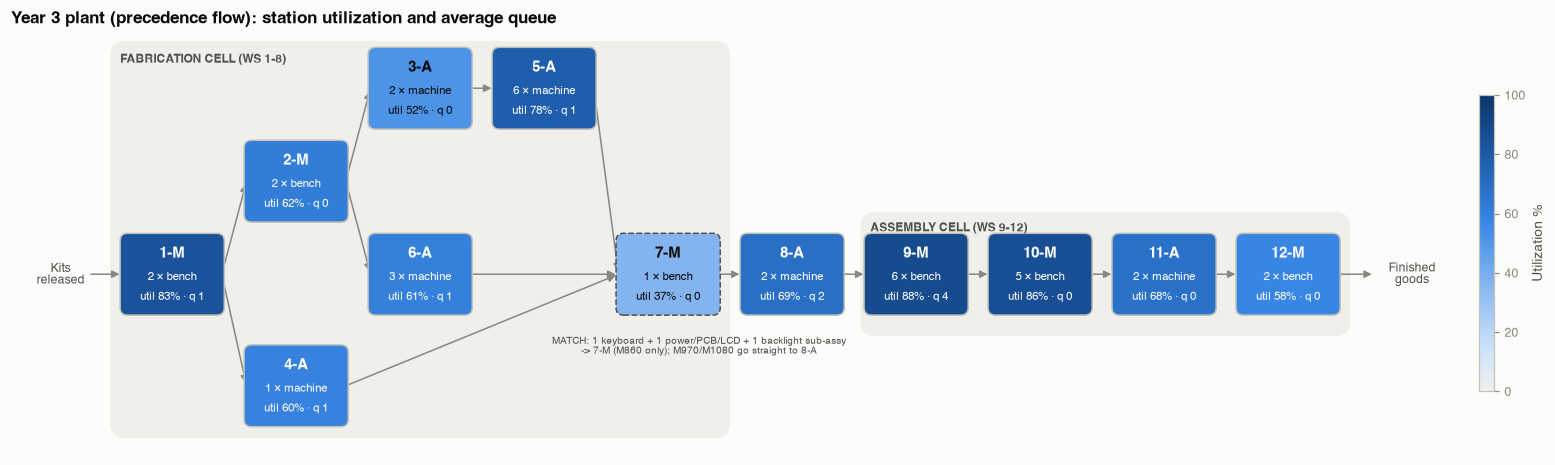

In [23]:
res = run(sc)
assert all(value == 0 for key, value in res.checks.items() if "must be 0" in key), res.checks
assert res.checks["max operator utilization (<= 1)"] <= 1 + 1e-9
assert (res.stations["Gate-blocked %"] == 0).all()
print("Accounting and operator checks:", res.checks)
P.plot_block_diagram(res); plt.show()


## 3. Throughput by product versus demand

Read each product separately: an equal M860/M970/M1080 arrival rotation can meet total demand while overproducing one model and underproducing another. Weekly output fluctuates with setups, maintenance, and scrap.

,Finished,Per week,Demand per week,% of demand,Avg flow time (hr),P90 flow time (hr)
Model,,,,,,
M860,"9,520.000","1,190.000","1,277.540",0.931,0.864,1.280
M970,"9,697.000","1,212.125","1,105.920",1.096,1.012,1.406
M1080,"9,672.000","1,209.000","1,230.320",0.983,1.175,1.502
Total,"28,889.000","3,611.125","3,613.780",0.999,1.018,1.415


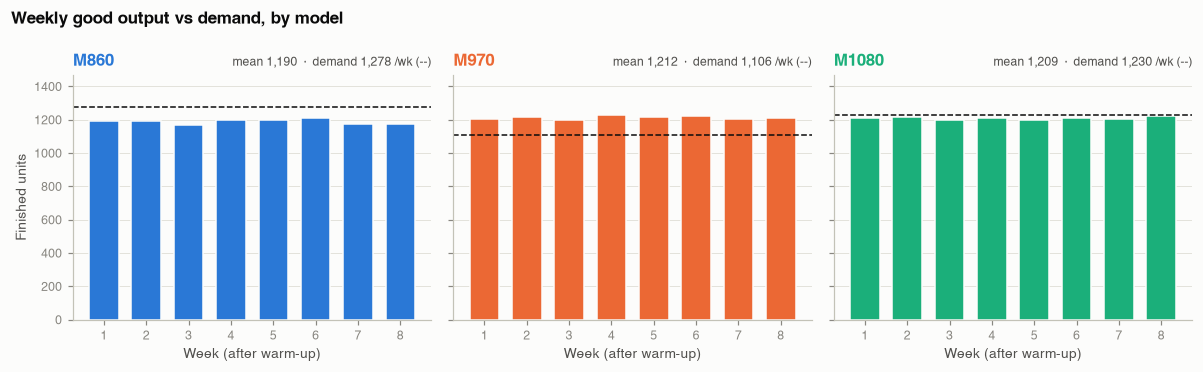

In [24]:
display(res.throughput)
P.plot_throughput(res); plt.show()


## 4. Queues, WIP, and matching

Daily station bars show waiting units by product; the detailed lines show the time pattern. No lot gates are used in this policy.

**Waiting at the match** is the component buffer after fabrication branches 4-A, 5-A, and 6-A. It is separate from station 7. One keyboard, one power/PCB/LCD, and one backlight subassembly from the same product lot must be available before an assembly moves to 7-M (M860) or directly to 8-A (M970/M1080). Waiting components count as WIP and occupy no operators or machines.

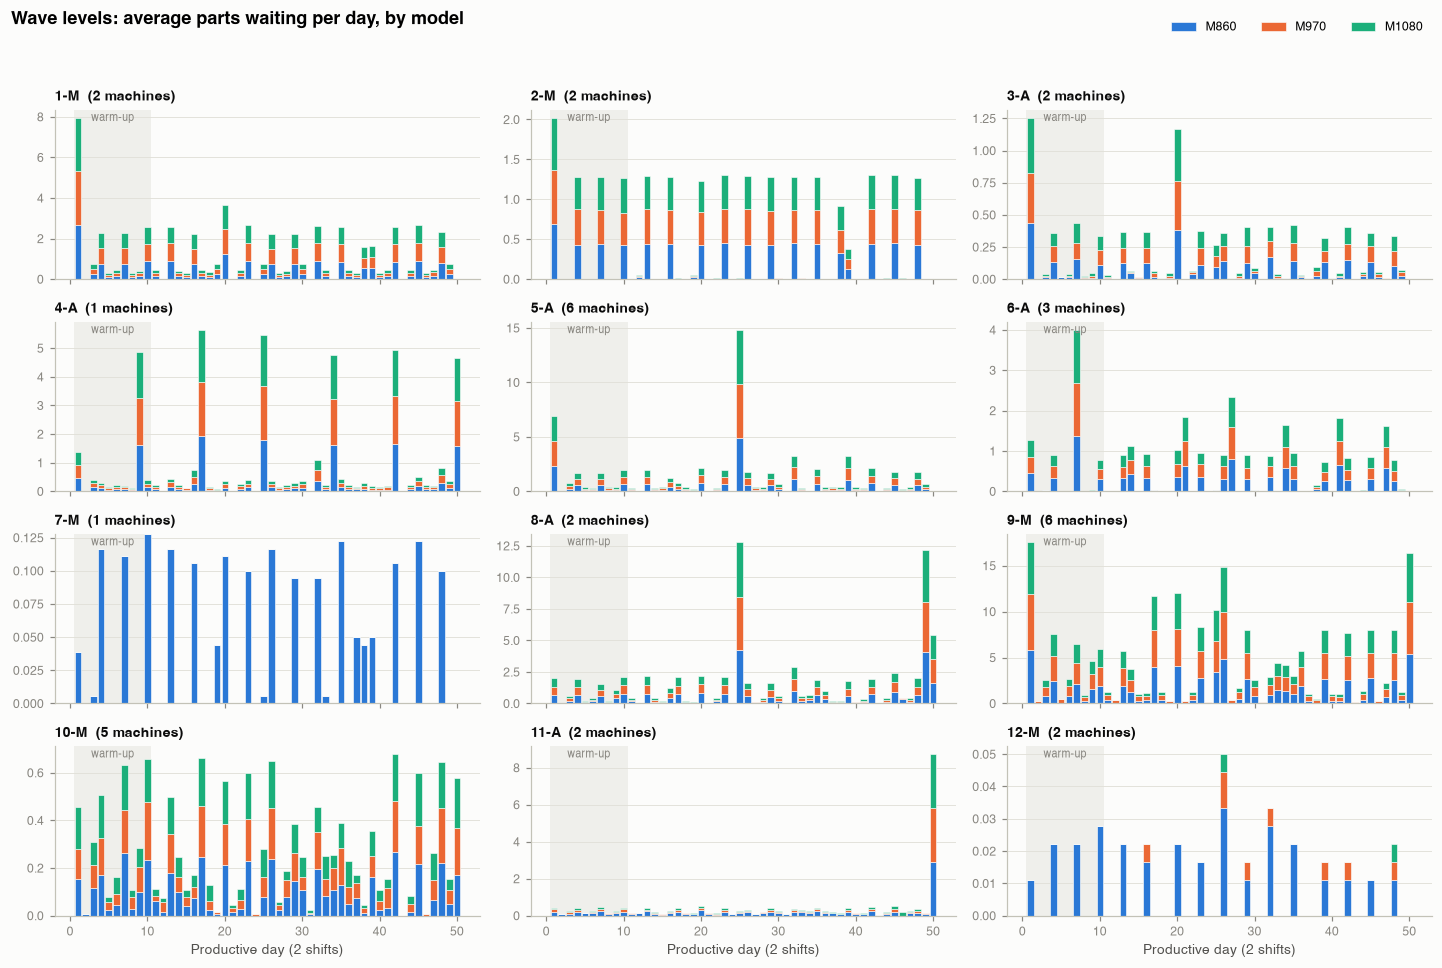

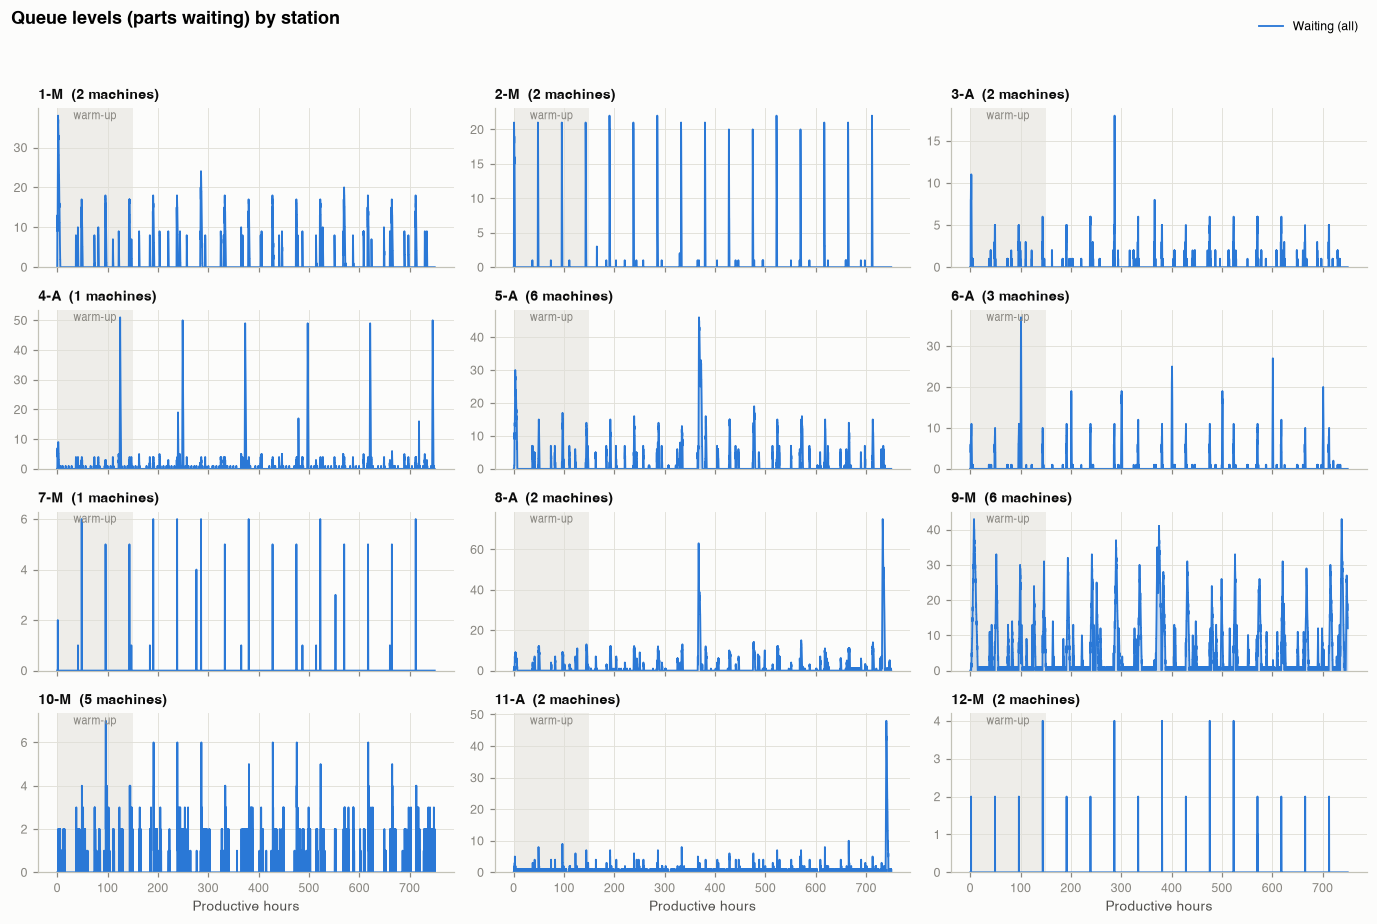

In [25]:
P.plot_wave_levels(res); plt.show()
P.plot_queue_lines(res, gated=False); plt.show()


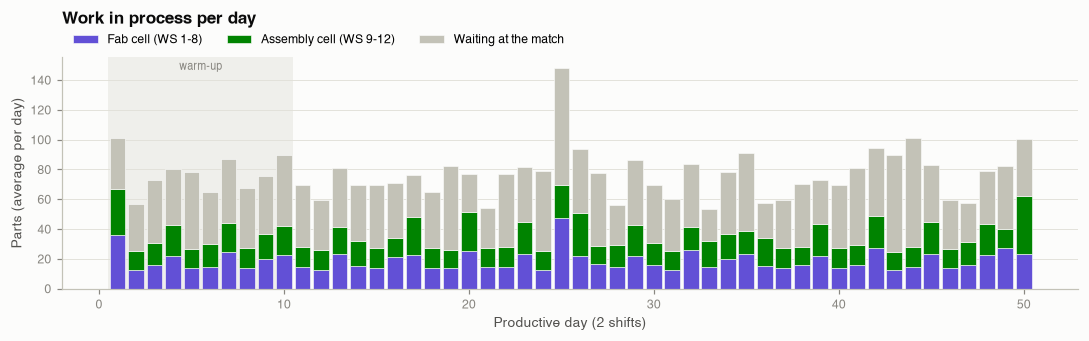

WIP near measurement start/end: 63 / 80 items
Net change: 17 items
Time-average WIP: 76.7 component/assembly items


In [26]:
P.plot_wip(res); plt.show()
window = res.trace[res.trace.t >= sc.warmup_min]
print(f"WIP near measurement start/end: {window.iloc[0]['WIP']:,.0f} / {window.iloc[-1]['WIP']:,.0f} items")
print(f"Net change: {window.iloc[-1]['WIP'] - window.iloc[0]['WIP']:,.0f} items")
print(f"Time-average WIP: {res.kpis['WIP|Average WIP (parts)']:,.1f} component/assembly items")


## 5. Station utilization and capacity

Utilization includes processing plus setup. The historical Phase 1 comparison and processing-only capacity estimates are reference values based on the original planned mix; the actual throughput, queue, and state-time measurements reflect this experiment's equal-thirds arrivals. Capacity bars exclude setup, operator waiting, and downtime.

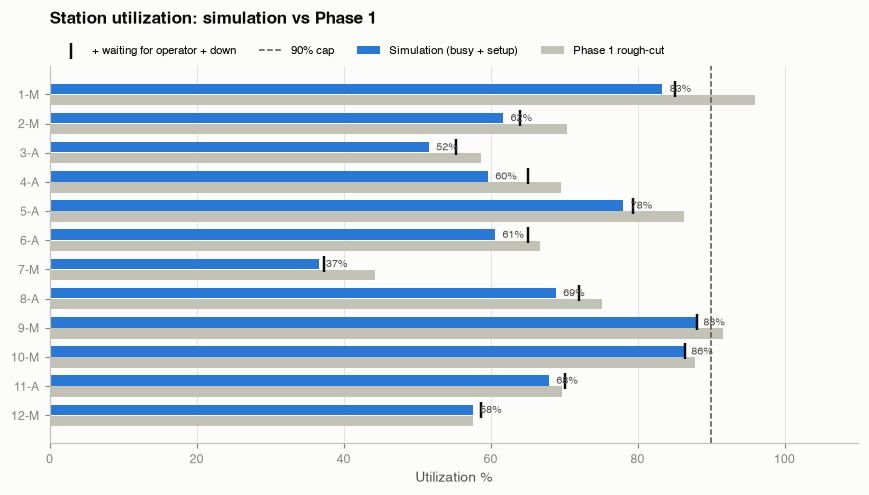

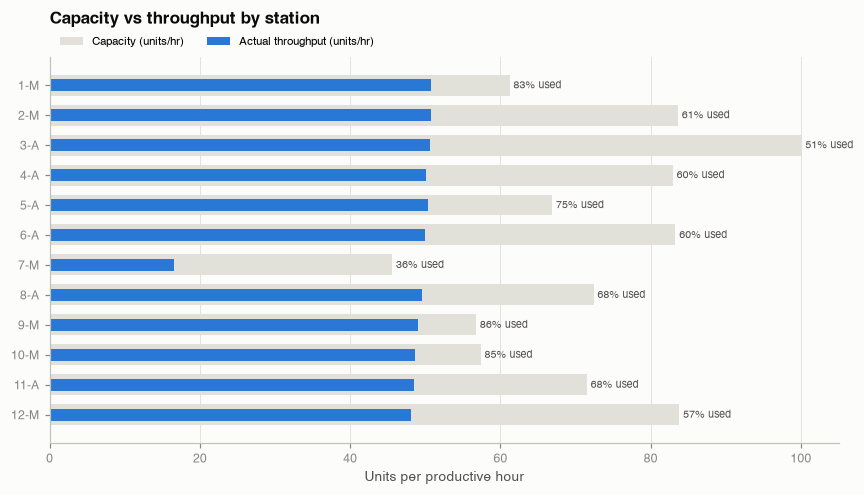

,Cell,Machines,Utilization,Busy %,Setup %,WaitOp %,Down %,Idle %,Capacity (units/hr),Throughput (units/hr),Avg queue,Max queue,Avg wait (min),Wait for operator (min/part),Group setups
Station,,,,,,,,,,,,,,,
1-M,Fab,2,0.834,0.828,0.006,0.018,0.000,0.149,61.230,50.703,1.020,25.000,1.207,0.041,12
2-M,Fab,2,0.617,0.610,0.007,0.021,0.001,0.361,83.642,50.702,0.390,22.000,0.462,0.050,12
3-A,Fab,2,0.516,0.514,0.003,0.032,0.005,0.447,100.091,50.588,0.161,19.000,0.191,0.075,43
4-A,Fab,1,0.597,0.593,0.003,0.045,0.010,0.349,82.950,50.117,0.875,51.000,1.047,0.053,43
5-A,Fab,6,0.781,0.766,0.015,0.007,0.006,0.206,66.894,50.392,1.185,46.000,1.411,0.031,43
6-A,Fab,3,0.606,0.603,0.004,0.034,0.011,0.349,83.299,49.958,0.534,27.000,0.642,0.122,12
7-M,Fab,1,0.366,0.362,0.004,0.006,0.001,0.627,45.605,16.495,0.035,6.000,0.127,0.022,12
8-A,Fab,2,0.689,0.685,0.004,0.026,0.006,0.279,72.403,49.512,1.592,76.000,1.929,0.063,43
9-M,Asm,6,0.880,0.878,0.002,0.001,0.000,0.119,56.767,49.073,4.079,43.000,4.987,0.009,12


In [27]:
P.plot_utilization(res); plt.show()
P.plot_capacity(res); plt.show()
display(res.stations[["Cell", "Machines", "Utilization", "Busy %", "Setup %", "WaitOp %", "Down %", "Idle %",
                      "Capacity (units/hr)", "Throughput (units/hr)", "Avg queue", "Max queue", "Avg wait (min)",
                      "Wait for operator (min/part)", "Group setups"]])


## 6. Machine states and individual machines

The station chart aggregates parallel machines. The heatmap and machine chart expose uneven loading. During a group setup, all participating machines are in Setup; while the setup team is being acquired, they are in Waiting for operator.

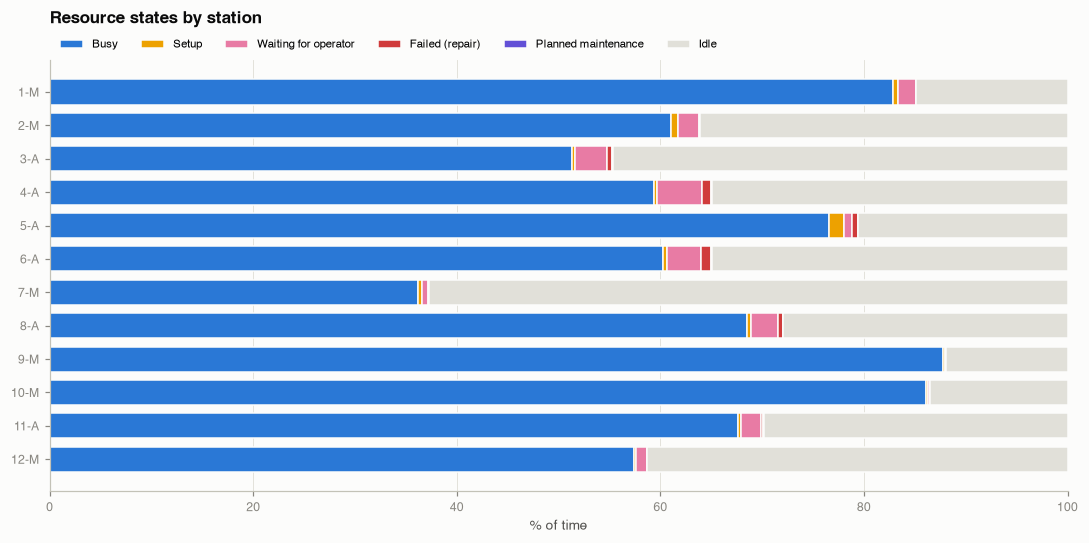

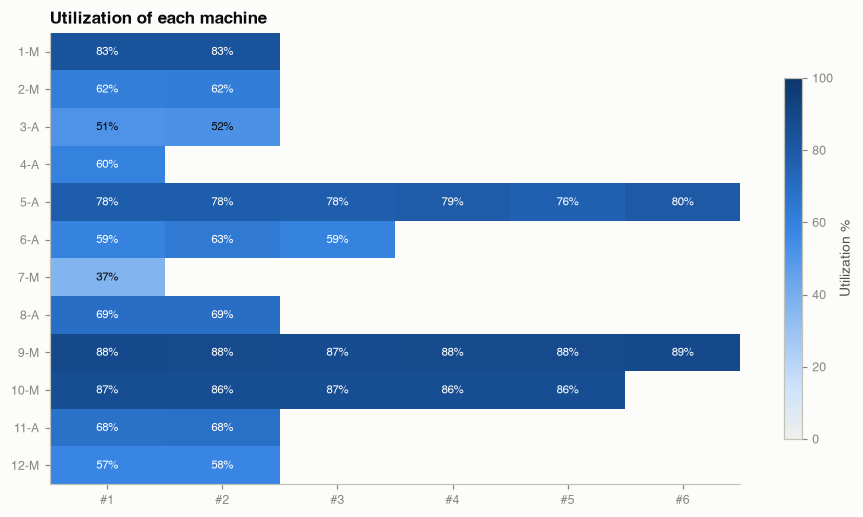

In [ ]:
P.plot_machine_states(res, by="station"); plt.show()
P.plot_machine_heatmap(res); plt.show()

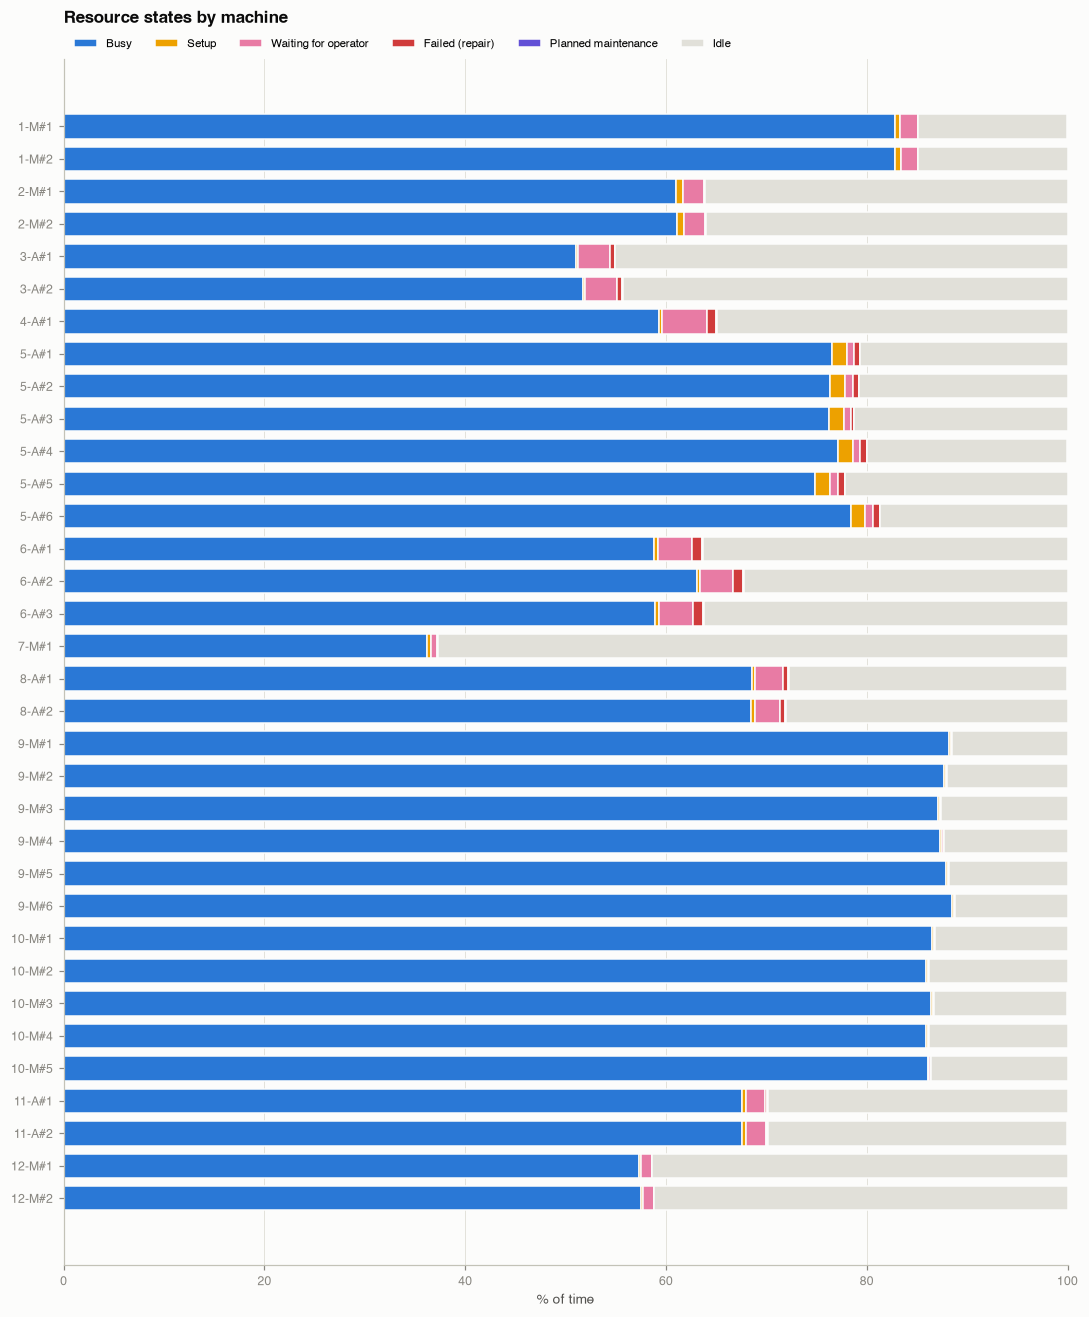

In [38]:
P.plot_machine_states(res, by="machine"); plt.show()
# display(res.machines)


## 7. Operator workload and activity

Setup crews draw from the same cell operator pools used for normal processing. Daily busy-operator plots show demand against staffing. Gantt charts show the first four logged hours after warm-up, with colors indicating station assignment; simultaneous team assignments appear on multiple operator rows.

,Crew per shift,Avg busy,Peak busy,Utilization,Avg WIP in cell,Avg wait for operator (min/part),Avg wait for machine (min/part)
Cell,,,,,,,
Fab,7,5.416,7.000,0.774,18.795,0.060,0.943
Asm,13,11.103,13.000,0.854,16.960,0.023,1.485


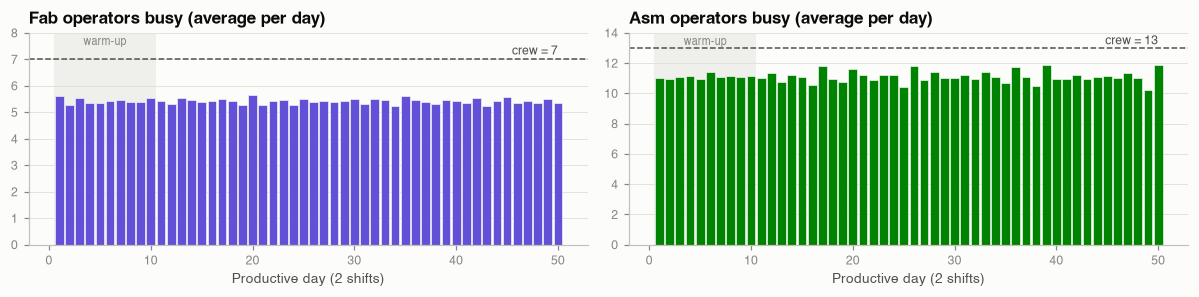

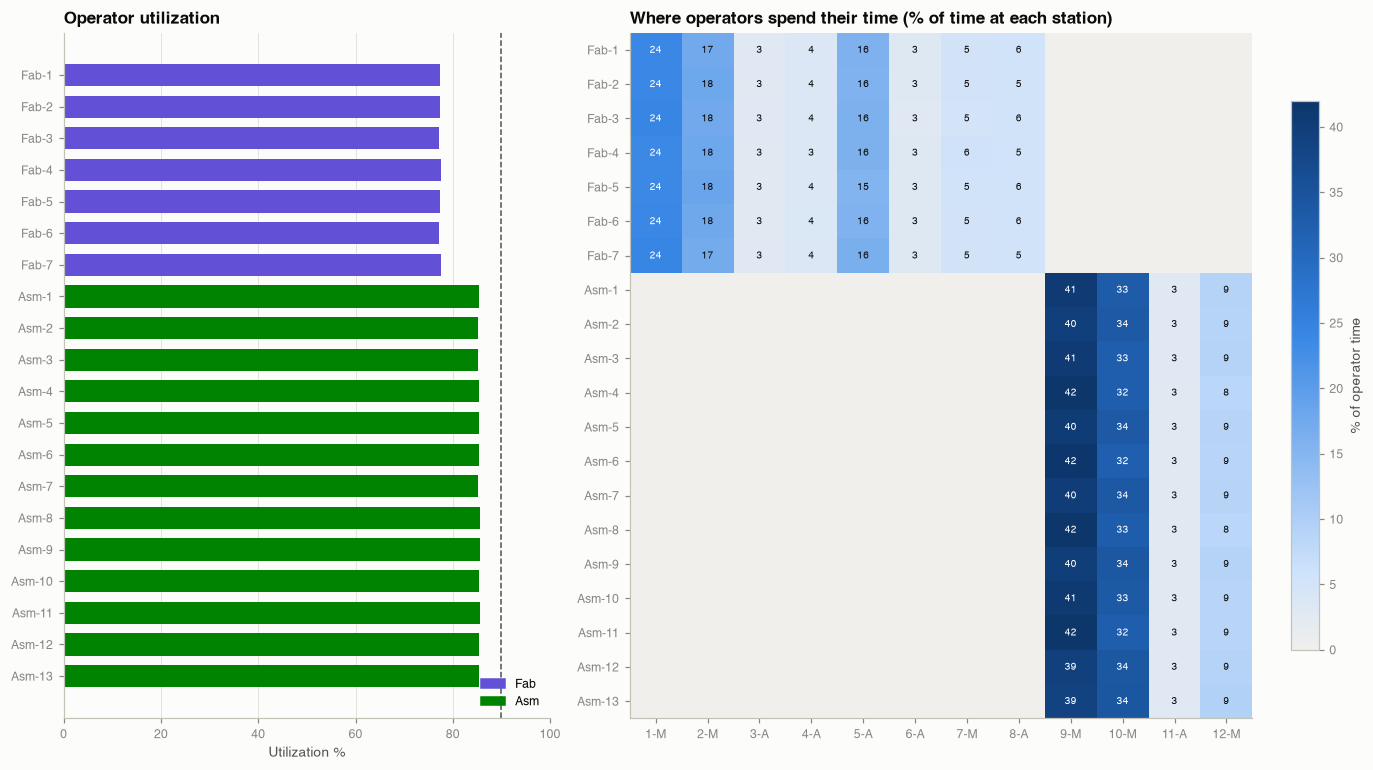

,Cell,Busy (hr),Utilization,Main station,1-M hr,2-M hr,3-A hr,4-A hr,5-A hr,6-A hr,7-M hr,8-A hr,9-M hr,10-M hr,11-A hr,12-M hr
Fab-1,Fab,463.836,0.773,1-M,142.900,104.700,17.000,21.200,94.900,18.700,31.400,33.200,0.000,0.000,0.000,0.000
Fab-2,Fab,464.036,0.773,1-M,142.900,106.600,16.400,21.600,94.100,18.600,31.300,32.600,0.000,0.000,0.000,0.000
Fab-3,Fab,462.958,0.772,1-M,143.800,105.000,16.900,21.100,95.500,17.300,30.200,33.100,0.000,0.000,0.000,0.000
Fab-4,Fab,465.593,0.776,1-M,141.800,106.600,16.200,20.900,95.800,18.700,33.500,32.200,0.000,0.000,0.000,0.000
Fab-5,Fab,464.531,0.774,1-M,141.300,109.800,16.100,21.400,92.000,19.100,31.600,33.100,0.000,0.000,0.000,0.000
Fab-6,Fab,463.230,0.772,1-M,143.400,105.600,16.400,21.800,93.700,18.200,30.900,33.300,0.000,0.000,0.000,0.000
Fab-7,Fab,465.109,0.775,1-M,144.600,102.400,16.800,21.200,98.200,18.400,30.800,32.800,0.000,0.000,0.000,0.000
Asm-1,Asm,512.710,0.855,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,244.700,196.700,16.700,54.500
Asm-2,Asm,510.800,0.851,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,237.900,201.500,17.400,54.000
Asm-3,Asm,511.629,0.853,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,244.200,195.500,17.100,54.800


In [30]:
display(res.cells)
P.plot_operators_busy(res); plt.show()
P.plot_operators(res); plt.show()
display(res.operators.join((res.op_station / 60).round(1).add_suffix(" hr")))


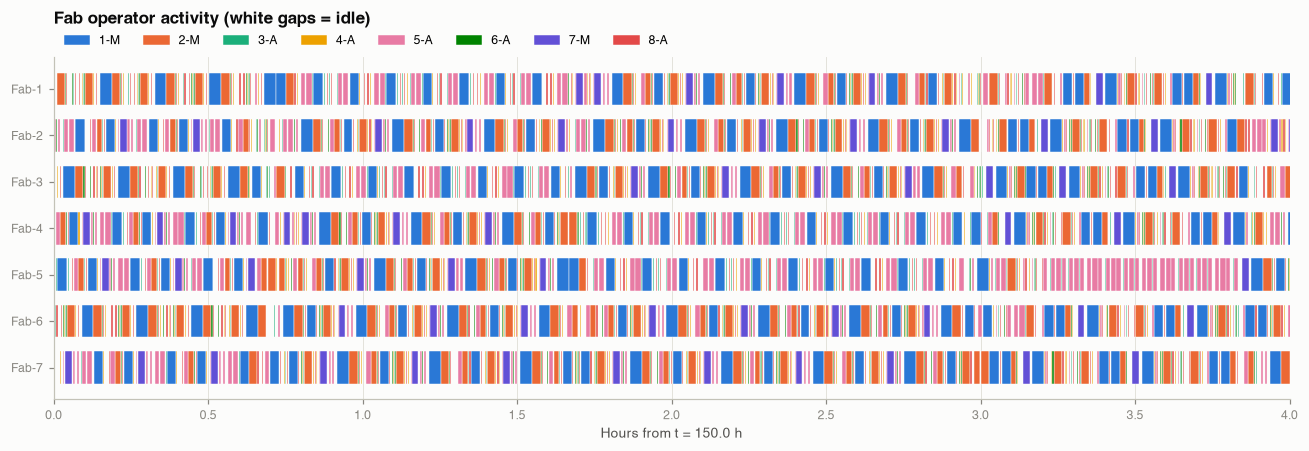

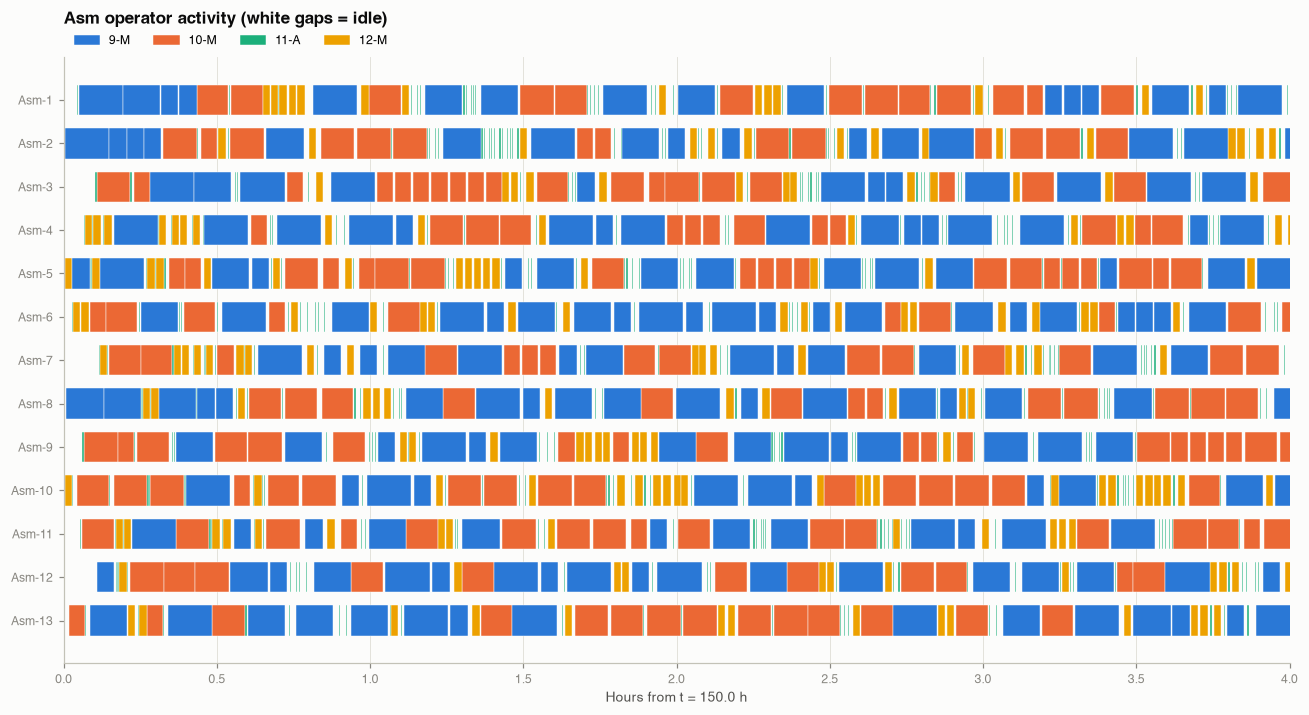

In [31]:
P.plot_operator_gantt(res, cell="Fab", hours=4); plt.show()
P.plot_operator_gantt(res, cell="Asm", hours=4); plt.show()


## 8. Station-group setups and team labor

Group setups count whole-station events during the measurement window. Machine setups count each participating machine: one event at 5-A contributes six machine setups. The event table and crew chart use the first logged week after warm-up; the event-count chart uses the complete eight-week measurement period.

,Station,Lot,Model,Start,End,Crew,Elapsed min,Operator min
0,1-M,16,M860,"11,375.653","11,392.320",2,16.667,33.333
1,10-M,16,M860,"11,467.056","11,472.611",5,5.556,27.778
2,11-A,14,M1080,"9,788.244","9,791.994",2,3.750,7.500
3,11-A,15,M970,"11,057.087","11,059.587",2,2.500,5.000
4,11-A,16,M860,"11,475.769","11,478.269",2,2.500,5.000
5,11-A,17,M1080,"12,220.037","12,223.787",2,3.750,7.500
6,11-A,18,M970,"13,258.369","13,260.869",2,2.500,5.000
7,12-M,16,M860,"11,479.943","11,484.705",2,4.762,9.524
8,2-M,16,M860,"11,394.062","11,415.115",2,21.053,42.105
9,3-A,14,M1080,"9,733.726","9,736.584",2,2.857,5.714


,Machines,Group setups,Setups,Setup %,WaitOp %
Station,,,,,
1-M,2,12,24,0.006,0.018
2-M,2,12,24,0.007,0.021
3-A,2,43,86,0.003,0.032
4-A,1,43,43,0.003,0.045
5-A,6,43,258,0.015,0.007
6-A,3,12,36,0.004,0.034
7-M,1,12,12,0.004,0.006
8-A,2,43,86,0.004,0.026
9-M,6,12,72,0.002,0.001


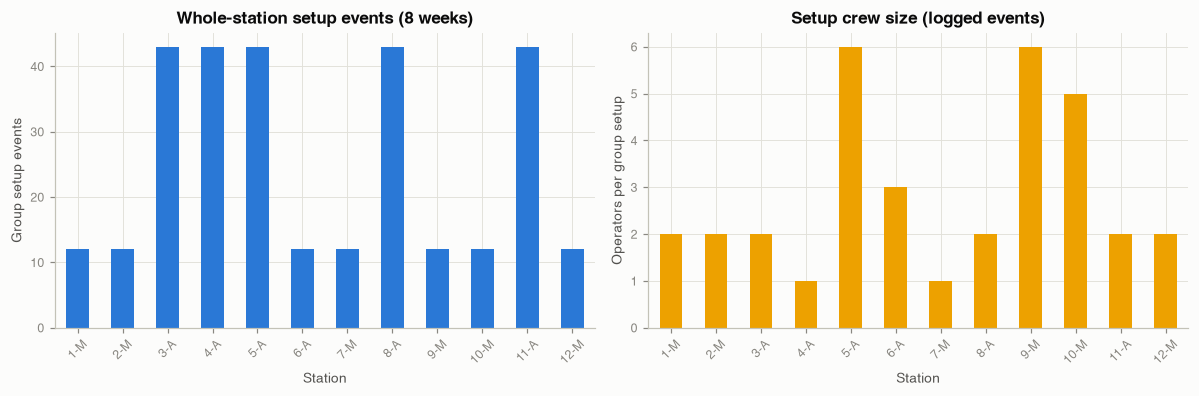

In [32]:
setup_tasks = res.op_log[res.op_log.Task == "setup"].copy()
events = pd.DataFrame()
if not setup_tasks.empty:
    events = setup_tasks.groupby(["Station", "Lot", "Model", "Start", "End"]).agg(Crew=("Operator", "nunique")).reset_index()
    events["Elapsed min"] = events.End - events.Start
    events["Operator min"] = events["Elapsed min"] * events.Crew
    display(events.head(25))
display(res.stations[["Machines", "Group setups", "Setups", "Setup %", "WaitOp %"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
res.stations["Group setups"].reindex(STATIONS).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
axes[0].set_title("Whole-station setup events (8 weeks)")
axes[0].set_ylabel("Group setup events")
if not events.empty:
    observed = events.groupby("Station").Crew.mean().reindex(STATIONS)
    observed.plot.bar(ax=axes[1], color="#eda100", rot=45)
axes[1].set_title("Setup crew size (logged events)")
axes[1].set_ylabel("Operators per group setup")
fig.tight_layout(); plt.show()


## 9. Scrap, spare components, and lot completion

Scrap is measured per entity: a kit, component, or assembled display. Unneeded branch outputs are counted as spare; unmatched components left when their accounting group closes are counted separately. EOQ identifiers are accounting and matching groups, not station processing restrictions.

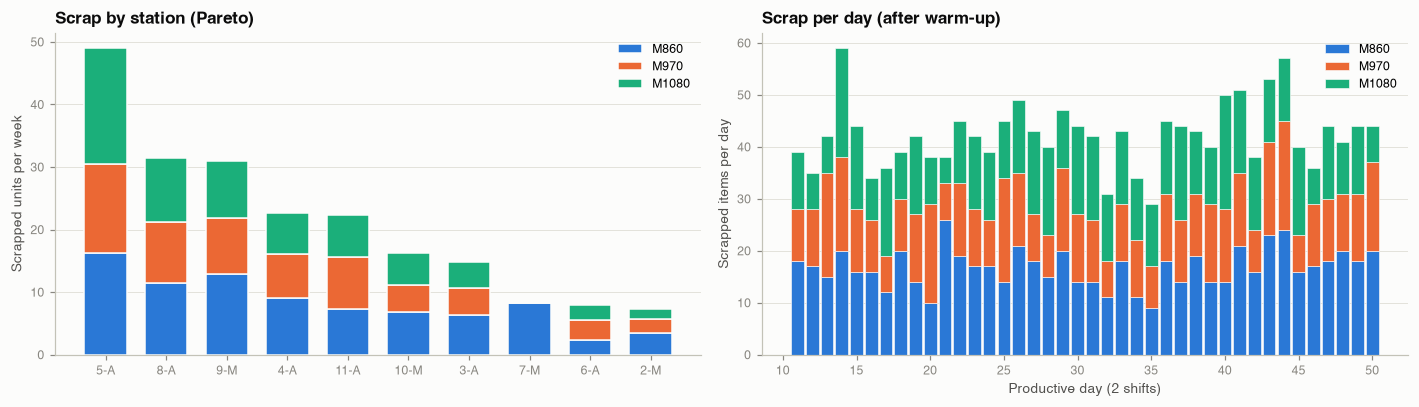

Units per week  Invested_min per week  Labor_dollars per week
Station Item                         Model                                                               
10-M    Display assembly             M1080           5.100                206.700                  40.600
                                     M860            6.800                149.600                  33.400
                                     M970            4.400                148.700                  30.300
11-A    Display assembly             M1080           6.600                279.000                  53.700
                                     M860            7.200                172.800                  36.900
                                     M970            8.400                297.900                  59.200
2-M     LCD/PCB set                  M1080           1.600                  6.400                   1.600
                                     M860            3.500                 10.100                   2.600
                                     M970            2.200                  7.600                   2.000
3-A     Power strip/PCB/LCD sub-assy M1080           4.200                 23.900                   4.700
                                     M860            6.400                 21.900                   5.100
                                     M970            4.200                 20.400                   4.000
4-A     Keyboard sub-assy            M1080           6.500                 19.300                   4.300
                                     M860            9.100                 24.700                   5.000
                                     M970            7.000                 16.300                   3.700
5-A     Power strip/PCB/LCD sub-assy M1080          18.500                238.200                  27.000
                                     M860           16.200                 99.700                  18.800
                                     M970           14.200                160.500                  18.500
6-A     Backlight/sensor sub-assy    M1080           2.500                 18.100                   2.700
                                     M860            2.400                  9.800                   1.900
                                     M970            3.100                 16.800                   2.900
7-M     Display assembly             M860            8.200                117.800                  23.600
8-A     Display assembly             M1080          10.200                257.900                  34.600
                                     M860           11.500                179.800                  34.300
                                     M970            9.800                200.000                  28.100
9-M     Display assembly             M1080           9.100                308.400                  58.700
                                     M860           12.900                244.700                  51.400
                                     M970            9.000                250.100                  45.500

,EOQ,Kits,Finished,Finished / EOQ,Short of EOQ,Scrapped,Spare,Unmatched,Yield (finished / kits),Planned yield,Lot flow time (hr)
Model,,,,,,,,,,,
M1080,655.000,685.000,652.833,0.997,2.667,35.556,19.389,5.944,0.953,0.957,41.021
M860,754.000,801.000,752.133,0.998,3.133,53.533,22.133,8.467,0.939,0.942,47.602
M970,596.000,620.000,593.650,0.996,3.500,29.750,11.800,7.300,0.957,0.961,37.299


In [33]:
P.plot_scrap(res); plt.show()
weeks = res.T / 4500
scr = res.scrap.groupby(["Station", "Item", "Model"]).agg(Units=("Part", "count"),
    Invested_min=("Invested min", "sum"), Labor_dollars=("Labor $", "sum"))
display((scr / weeks).round(1).rename(columns=lambda c: c + " per week"))
lots = res.lots.dropna(subset=["Done"])
display(lots.groupby("Model")[["EOQ", "Kits", "Finished", "Finished / EOQ", "Short of EOQ", "Scrapped", "Spare",
    "Unmatched", "Yield (finished / kits)", "Planned yield", "Lot flow time (hr)"]].mean())


## 10. Individual-display flow time

Flow time starts at the actual arrival of the oldest constituent kit and ends at finished-display departure. It includes setup, queues, matching, downtime, and processing. The distribution is distinct from whole-lot completion time.

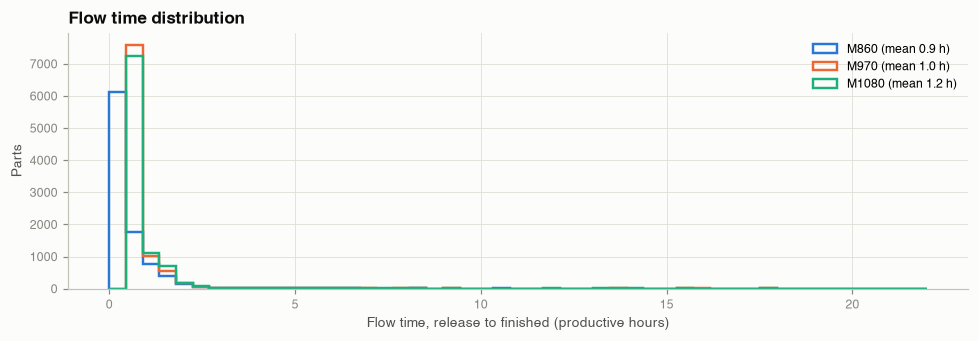

,Avg flow time (hr),P90 flow time (hr)
Model,,
M860,0.864,1.280
M970,1.012,1.406
M1080,1.175,1.502
Total,1.018,1.415


In [34]:
P.plot_flow_time(res); plt.show()
display(res.throughput[["Avg flow time (hr)", "P90 flow time (hr)"]])


## 11. Replications and policy comparisons

Each policy uses ten replications with seeds 1–10. The no-SPC references retain original scrap probabilities. Compare the two station-group policies to assess SPC under the same resources, setup rules, and product rotation. SPC also reduces planned scrap allowances and therefore input kit requirements and arrival frequency; demand targets are unchanged. Continuous product runs retain the earlier demand-weighted mix, while the rotation policies use equal thirds. Event ordering can change individual scrap outcomes. Reported half-widths are 95% confidence intervals for the mean.


In [35]:
policies = {
    "Continuous product runs": get_scenario(YEAR, release_mode="continuous"),
    "Unit rotation: machine changeovers": get_scenario(YEAR, release_mode="cyclic"),
    "Unit rotation: assumptions (no SPC)": replace(sc, scrap_scale=1.0),
    "Unit rotation: assumptions": sc,
}
summaries = {}
for name, scenario in policies.items():
    print("Running:", name, flush=True)
    _, summaries[name] = run_replications(scenario, n=N_REPS, n_jobs=N_JOBS)
keys = [
    ("WIP", "Average WIP (parts)"), ("WIP", "Ending WIP (parts)"),
    ("Throughput", "Total per week"), ("Throughput", "% of demand"),
    *[("Throughput", f"{model} per week") for model in MODELS],
    *[("Flow time (hr)", model) for model in MODELS],
    ("Scrap", "Items scrapped per week"),
    ("Operators", "Fab utilization"), ("Operators", "Asm utilization"),
]
comparison = pd.concat([summary.loc[keys, "Average"].rename(name) for name, summary in summaries.items()], axis=1)
display(comparison)
assumptions_summary = summaries["Unit rotation: assumptions"]
display(assumptions_summary.loc[keys, ["Average", "Half Width", "Minimum", "Maximum"]])
comparison.to_csv("phase2_assumptions_comparison.csv")


Running: Continuous product runs
Running: Unit rotation: machine changeovers
Running: Unit rotation: assumptions (no SPC)
Running: Unit rotation: assumptions


Continuous product runs  Unit rotation: machine changeovers  Unit rotation: assumptions (no SPC)  Unit rotation: assumptions
Category       Statistic                                                                                                                                            
WIP            Average WIP (parts)                      940.680                          36,496.965                              180.025                      72.389
               Ending WIP (parts)                       754.000                          60,729.000                              159.300                      76.900
Throughput     Total per week                         3,608.675                             644.275                            3,618.213                   3,614.613
               % of demand                                0.999                               0.178                                1.001                       1.000
               M860 per week                          1,311.150                             204.675                            1,148.275                   1,189.375
               M970 per week                          1,110.062                             223.225                            1,246.450                   1,216.425
               M1080 per week                         1,187.463                             216.375                            1,223.487                   1,208.812
Flow time (hr) M860                                      14.468                             382.046                                1.964                       0.801
               M970                                      15.102                             380.197                                1.609                       0.936
               M1080                                     13.184                             379.646                                2.090                       1.073
Scrap          Items scrapped per week                  933.350                             239.900                              912.362                     207.600
Operators      Fab utilization                            0.881                               1.000                                0.877                       0.769
               Asm utilization                            0.870                               0.175                                0.894                       0.854

Average  Half Width   Minimum   Maximum
Category       Statistic                                                        
WIP            Average WIP (parts)        72.389       2.688    67.616    79.945
               Ending WIP (parts)         76.900       7.663    61.000    98.000
Throughput     Total per week          3,614.613       2.084 3,609.000 3,619.750
               % of demand                 1.000       0.001     0.999     1.002
               M860 per week           1,189.375       2.134 1,184.250 1,193.125
               M970 per week           1,216.425       0.999 1,213.375 1,218.375
               M1080 per week          1,208.812       1.062 1,206.750 1,210.625
Flow time (hr) M860                        0.801       0.040     0.720     0.918
               M970                        0.936       0.039     0.874     1.055
               M1080                       1.073       0.064     0.985     1.271
Scrap          Items scrapped per week   207.600       1.733   204.125   210.875
Operators      Fab utilization             0.769       0.000     0.769     0.770
               Asm utilization             0.854       0.000     0.853     0.854

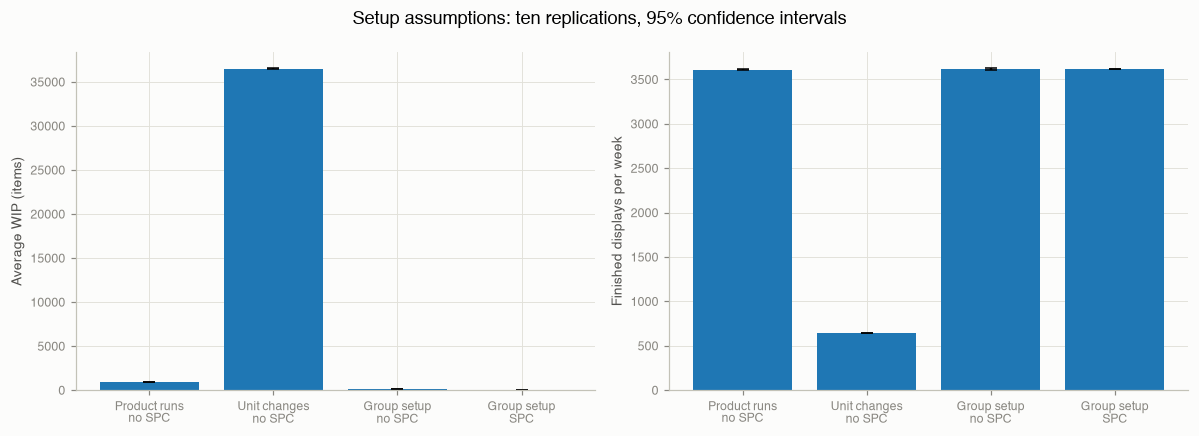

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, label in zip(axes, [("WIP", "Average WIP (parts)"), ("Throughput", "Total per week")],
                         ["Average WIP (items)", "Finished displays per week"]):
    means = [summary.loc[key, "Average"] for summary in summaries.values()]
    errors = [summary.loc[key, "Half Width"] for summary in summaries.values()]
    ax.bar(["Product runs\nno SPC", "Unit changes\nno SPC", "Group setup\nno SPC", "Group setup\nSPC"], means, yerr=errors, capsize=4)
    ax.set_ylabel(label)
fig.suptitle("Setup assumptions: ten replications, 95% confidence intervals")
fig.tight_layout(); plt.show()


## 12. Bottlenecks across replications

Station utilization and average queues are averaged across the assumptions-policy replications. High utilization and persistent queues identify constraints; machine Setup and Waiting for operator states explain capacity losses.

,Avg utilization (10 reps),Avg queue (10 reps),Machines,Setup %,WaitOp %,Group setups
Statistic,,,,,,
9-M,0.879,2.890,6,0.002,0.001,12
10-M,0.863,0.167,5,0.002,0.001,12
1-M,0.830,0.360,2,0.006,0.018,12
5-A,0.781,1.132,6,0.015,0.007,43
8-A,0.689,1.175,2,0.004,0.026,43
11-A,0.680,0.401,2,0.004,0.020,43
2-M,0.612,0.034,2,0.007,0.021,12
6-A,0.603,0.209,3,0.004,0.034,12
4-A,0.597,0.782,1,0.003,0.045,43


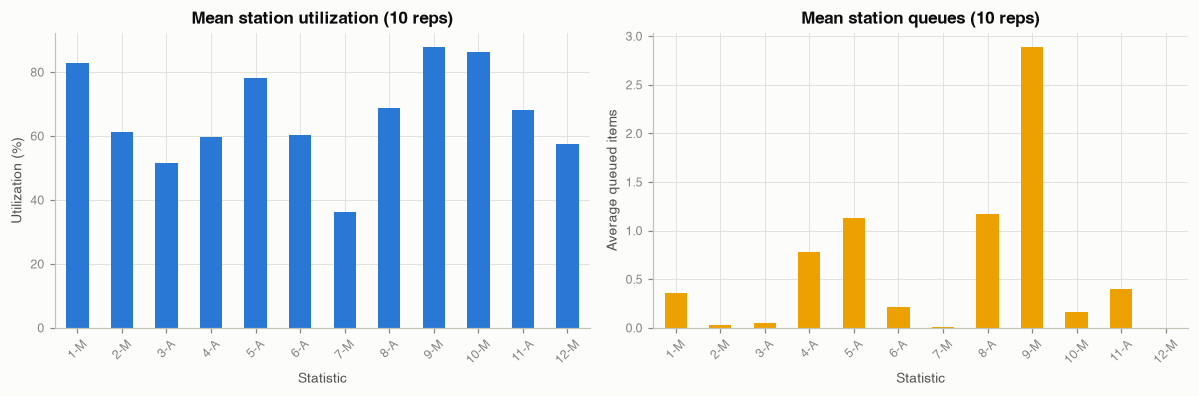

Average  Half Width   Minimum   Maximum
Category            Statistic                                                                    
Throughput          M860 per week                       1,189.375       2.134 1,184.250 1,193.125
                    M970 per week                       1,216.425       0.999 1,213.375 1,218.375
                    M1080 per week                      1,208.812       1.062 1,206.750 1,210.625
                    Total per week                      3,614.613       2.084 3,609.000 3,619.750
                    % of demand                             1.000       0.001     0.999     1.002
Flow time (hr)      M860                                    0.801       0.040     0.720     0.918
                    M970                                    0.936       0.039     0.874     1.055
                    M1080                                   1.073       0.064     0.985     1.271
WIP                 Average WIP (parts)                    72.389       2.688    67.616    79.945
                    Ending WIP (parts)                     76.900       7.663    61.000    98.000
Operators           Fab utilization                         0.769       0.000     0.769     0.770
                    Fab wait for operator (min/part)        0.048       0.000     0.047     0.048
                    Asm utilization                         0.854       0.000     0.853     0.854
                    Asm wait for operator (min/part)        0.017       0.001     0.016     0.019
Station utilization 1-M                                     0.830       0.000     0.830     0.830
                    2-M                                     0.612       0.000     0.612     0.612
                    3-A                                     0.516       0.000     0.516     0.516
                    4-A                                     0.597       0.000     0.597     0.597
                    5-A                                     0.781       0.000     0.780     0.781
                    6-A                                     0.603       0.000     0.603     0.604
                    7-M                                     0.363       0.000     0.362     0.364
                    8-A                                     0.689       0.000     0.688     0.689
                    9-M                                     0.879       0.000     0.878     0.880
                    10-M                                    0.863       0.001     0.862     0.864
                    11-A                                    0.680       0.000     0.679     0.681
                    12-M                                    0.575       0.000     0.574     0.576
Avg queue           1-M                                     0.360       0.003     0.355     0.372
                    2-M                                     0.034       0.001     0.032     0.038
                    3-A                                     0.047       0.004     0.041     0.058
                    4-A                                     0.782       0.006     0.771     0.794
                    5-A                                     1.132       0.612     0.321     3.164
                    6-A                                     0.209       0.083     0.049     0.391
                    7-M                                     0.008       0.000     0.007     0.008
                    8-A                                     1.175       0.203     0.573     1.531
                    9-M                                     2.890       0.545     2.061     4.497
                    10-M                                    0.167       0.007     0.153     0.185
                    11-A                                    0.401       0.035     0.323     0.458
                    12-M                                    0.001       0.000     0.001     0.001
Down %              1-M                                     0.000       0.000     0.000     0.000
                    2-M                 

In [37]:
summary = assumptions_summary
avg_util = summary.xs("Station utilization").Average.rename("Avg utilization (10 reps)")
avg_q = summary.xs("Avg queue").Average.rename("Avg queue (10 reps)")
bottlenecks = pd.concat([avg_util, avg_q], axis=1).join(res.stations[["Machines", "Setup %", "WaitOp %", "Group setups"]])
display(bottlenecks.sort_values("Avg utilization (10 reps)", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
avg_util.reindex(STATIONS).mul(100).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
axes[0].set_ylabel("Utilization (%)")
axes[0].set_title("Mean station utilization (10 reps)")
avg_q.reindex(STATIONS).plot.bar(ax=axes[1], color="#eda100", rot=45)
axes[1].set_ylabel("Average queued items")
axes[1].set_title("Mean station queues (10 reps)")
fig.tight_layout(); plt.show()
display(summary)
